# 实验报告02：NumPy 与 pandas 数据处理
学号：20244080119
姓名：李奕昕
环境：py_exp

### 任务 0：身份与环境记录
使用当前 Conda 环境运行本 Notebook，不在单元格中安装依赖。

In [45]:
import os
import sys
import uuid
import hashlib
import platform

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
matplotlib.rcParams["axes.unicode_minus"] = False

STUDENT_ID = 20244080119
conda_env = os.environ.get("CONDA_DEFAULT_ENV", "未检测到 CONDA_DEFAULT_ENV")
machine_info = (
    f"{platform.node()}|{platform.machine()}|"
    f"{platform.system()}|{uuid.getnode()}"
)
machine_fp = hashlib.sha256(machine_info.encode()).hexdigest()[:16]
run_id = f"{STUDENT_ID}-{machine_fp}"

print(f"[Conda 环境] {conda_env}")
print(f"[Python 解释器] {sys.executable}")
print(f"[NumPy] {np.__version__}")
print(f"[SciPy] {scipy.__version__}")
print(f"[Matplotlib] {matplotlib.__version__}")
print(f"[pandas] {pd.__version__}")
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {machine_fp}")
print(f"[RUN_ID] {run_id}")

[Conda 环境] py_exp
[Python 解释器] d:\Anaconda\envs\py_exp\python.exe
[NumPy] 2.4.6
[SciPy] 1.17.1
[Matplotlib] 3.11.2
[pandas] 3.0.6
[学号] 20244080119
[机器指纹] 60bb97c2c4e89b33
[RUN_ID] 20244080119-60bb97c2c4e89b33


### 任务 1.1：创建不同数据类型的 NumPy 数组
NumPy 数组通常要求元素具有统一的数据类型；Python 列表可以包含不同类型的元素。

In [46]:
int_array = np.array([1, 2, 3, 4])
float_array = np.array([1.5, 2.5, 3.5])
bool_array = np.array([True, False, True])

for name, array in {
    "整数数组": int_array,
    "浮点数数组": float_array,
    "布尔数组": bool_array,
}.items():
    print(f"{name}: {array}")
    print(f"  dtype={array.dtype}, shape={array.shape}, ndim={array.ndim}")

mixed_list = [1, "two", 3.0]
mixed_array = np.array(mixed_list)
print(f"\nPython 混合类型列表: {mixed_list}")
print(f"NumPy 根据统一类型创建的数组: {mixed_array}")
print(f"NumPy 数组 dtype: {mixed_array.dtype}")

整数数组: [1 2 3 4]
  dtype=int64, shape=(4,), ndim=1
浮点数数组: [1.5 2.5 3.5]
  dtype=float64, shape=(3,), ndim=1
布尔数组: [ True False  True]
  dtype=bool, shape=(3,), ndim=1

Python 混合类型列表: [1, 'two', 3.0]
NumPy 根据统一类型创建的数组: ['1' 'two' '3.0']
NumPy 数组 dtype: <U32


### 任务 1.2：创建数组并改变形状
改变形状时元素总数必须保持不变，新形状各维度乘积应等于原数组元素个数。

In [47]:
one_dimensional = np.arange(12)
array_3x4 = one_dimensional.reshape(3, 4)
array_2x3x2 = one_dimensional.reshape(2, 3, 2)

print(f"一维数组: {one_dimensional}")
print(f"元素个数: {one_dimensional.size}")
print(f"\n形状 {array_3x4.shape}:")
print(array_3x4)
print(f"\n形状 {array_2x3x2.shape}:")
print(array_2x3x2)

一维数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]
元素个数: 12

形状 (3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状 (2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


### 任务 1.3：二维数组索引
按从 1 开始计数，第 1 至第 3 列使用切片 `0:3`。布尔索引选出的元素组成一维数组。

In [48]:
array_3x4 = np.arange(12).reshape(3, 4)
second_row = array_3x4[1, :]
first_to_third_columns = array_3x4[:, 0:3]
greater_than_six = array_3x4[array_3x4 > 6]

print("原数组:")
print(array_3x4)
print(f"\n第 2 行: {second_row}; shape={second_row.shape}")
print(f"\n第 1 至第 3 列:\n{first_to_third_columns}")
print(f"shape={first_to_third_columns.shape}")
print(f"\n大于 6 的元素: {greater_than_six}; shape={greater_than_six.shape}")

原数组:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行: [4 5 6 7]; shape=(4,)

第 1 至第 3 列:
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
shape=(3, 3)

大于 6 的元素: [ 7  8  9 10 11]; shape=(5,)


### 任务 1.4：使用逻辑条件进行布尔索引
`|` 表示“或”，`&` 表示“且”；使用括号明确各个比较条件。

In [49]:
array = np.arange(10)
outside_middle = array[(array < 2) | (array > 7)]
between_three_and_seven = array[(array > 3) & (array < 7)]

print(f"原数组: {array}")
print(f"小于 2 或大于 7: {outside_middle}")
print(f"大于 3 且小于 7: {between_three_and_seven}")

原数组: [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7: [0 1 8 9]
大于 3 且小于 7: [4 5 6]


### 任务 1.5：逐元素乘法与矩阵乘法
`*` 与 `np.multiply` 是逐元素相乘；`@` 与 `np.matmul` 执行矩阵乘法。

In [50]:
array_a = np.array([[1, 2], [3, 4]])
array_b = np.array([[5, 6], [7, 8]])

print(f"A:\n{array_a}\nB:\n{array_b}")
print(f"\nA * B（逐元素）:\n{array_a * array_b}")
print(f"np.multiply(A, B)（逐元素）:\n{np.multiply(array_a, array_b)}")
print(f"\nA @ B（矩阵乘法）:\n{array_a @ array_b}")
print(f"np.matmul(A, B)（矩阵乘法）:\n{np.matmul(array_a, array_b)}")

A:
[[1 2]
 [3 4]]
B:
[[5 6]
 [7 8]]

A * B（逐元素）:
[[ 5 12]
 [21 32]]
np.multiply(A, B)（逐元素）:
[[ 5 12]
 [21 32]]

A @ B（矩阵乘法）:
[[19 22]
 [43 50]]
np.matmul(A, B)（矩阵乘法）:
[[19 22]
 [43 50]]


### 任务 2.1：生成模拟成绩并计算统计量
固定随机种子以便复现；使用 `np.clip` 将成绩限制在 0 到 100 之间。

In [51]:
np.random.seed(2026)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print(f"样本数: {scores.size}")
print(f"最小值: {np.min(scores):.2f}")
print(f"最大值: {np.max(scores):.2f}")
print(f"均值: {np.mean(scores):.2f}")
print(f"标准差: {np.std(scores):.2f}")
print(f"极差: {np.ptp(scores):.2f}")

样本数: 1000
最小值: 37.27
最大值: 100.00
均值: 70.74
标准差: 10.25
极差: 62.73


### 任务 2.2：不放回随机抽样
均匀抽样不指定概率；加权抽样将整数本身作为权重并归一化。

In [52]:
np.random.seed(2026)
population = np.arange(1, 11)
uniform_sample = np.random.choice(population, size=5, replace=False)
weights = population / population.sum()
weighted_sample = np.random.choice(
    population, size=5, replace=False, p=weights
)

print(f"总体: {population}")
print(f"均匀不放回抽样: {uniform_sample}")
print(f"按整数大小成比例的权重: {weights}")
print(f"加权不放回抽样: {weighted_sample}")

总体: [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样: [ 8  4 10  9  5]
按整数大小成比例的权重: [0.01818182 0.03636364 0.05454545 0.07272727 0.09090909 0.10909091
 0.12727273 0.14545455 0.16363636 0.18181818]
加权不放回抽样: [ 9  6  3  8 10]


### 任务 2.3：随机排列与原地打乱
`np.random.permutation` 返回新数组；`np.random.shuffle` 原地修改传入数组。

In [53]:
np.random.seed(2026)
original = np.arange(1, 11)
permuted = np.random.permutation(original)
array_to_shuffle = original.copy()
before_shuffle = array_to_shuffle.copy()
np.random.shuffle(array_to_shuffle)

print(f"原数组: {original}")
print(f"permutation 返回的新数组: {permuted}")
print(f"permutation 后原数组: {original}")
print(f"shuffle 前副本: {before_shuffle}")
print(f"shuffle 原地打乱后: {array_to_shuffle}")

原数组: [ 1  2  3  4  5  6  7  8  9 10]
permutation 返回的新数组: [ 8  4 10  9  5  6  1  3  7  2]
permutation 后原数组: [ 1  2  3  4  5  6  7  8  9 10]
shuffle 前副本: [ 1  2  3  4  5  6  7  8  9 10]
shuffle 原地打乱后: [10  5  8  9  2  1  4  6  7  3]


### 任务 2.4：处理缺失值并比较均值
普通均值遇到 `np.nan` 会得到 `nan`；`np.nanmean` 会忽略缺失值。

In [54]:
np.random.seed(2026)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan

print(f"含缺失值的普通均值: {np.mean(scores_with_nan)}")
print(f"忽略缺失值后的均值: {np.nanmean(scores_with_nan):.2f}")
print(f"缺失值个数: {np.isnan(scores_with_nan).sum()}")
print(f"有效成绩个数: {np.isfinite(scores_with_nan).sum()}")

含缺失值的普通均值: nan
忽略缺失值后的均值: 70.76
缺失值个数: 3
有效成绩个数: 997


### 任务 2.5：将成绩整理成内存中的表格
创建 `scores_df` 供后续绘图和 CSV 内存读写使用，不写入磁盘。

In [55]:
sample_numbers = np.arange(1, len(scores_with_nan) + 1)
scores_df = pd.DataFrame(
    {"Score": scores_with_nan},
    index=pd.Index(sample_numbers, name="SampleNo"),
)

print("成绩表前 5 行:")
print(scores_df.head())
print(f"\n表格形状: {scores_df.shape}")
print(f"缺失值个数: {scores_df['Score'].isna().sum()}")
print(f"有效成绩均值: {scores_df['Score'].mean():.2f}")

成绩表前 5 行:
              Score
SampleNo           
1         65.682815
2         56.071260
3         73.115707
4         69.867651
5         84.497077

表格形状: (1000, 1)
缺失值个数: 3
有效成绩均值: 70.76


### 任务 3.1：使用 SciPy 解线性方程组
求解 `3x + y = 9`、`x + 2y = 8`，并使用 NumPy 代入验证。

In [56]:
from scipy.linalg import solve

coefficients = np.array([[3, 1], [1, 2]], dtype=float)
right_hand_side = np.array([9, 8], dtype=float)
solution = solve(coefficients, right_hand_side)
verified_left_hand_side = coefficients @ solution

print(f"解: x={solution[0]:.6f}, y={solution[1]:.6f}")
print(f"代入左侧: {verified_left_hand_side}")
print(f"方程右侧: {right_hand_side}")
print(f"满足原方程: {np.allclose(verified_left_hand_side, right_hand_side)}")

解: x=2.000000, y=3.000000
代入左侧: [9. 8.]
方程右侧: [9. 8.]
满足原方程: True


### 任务 3.2：使用 SciPy 求方程的正根和负根
对方程 `x**2 - 2 = 0` 分别使用正、负初始猜测值，并检查函数残差。

In [57]:
from scipy.optimize import root

def equation(value):
    return value**2 - 2

for initial_guess in (1.0, -1.0):
    result = root(equation, x0=initial_guess)
    root_value = float(result.x[0])
    residual = equation(root_value)
    print(f"初始猜测值: {initial_guess}")
    print(f"求根是否成功: {result.success}")
    print(f"求得的根: {root_value:.10f}")
    print(f"函数值 f(x): {residual:.3e}")
    print(f"函数值是否接近 0: {np.isclose(residual, 0, atol=1e-8)}\n")

初始猜测值: 1.0
求根是否成功: True
求得的根: 1.4142135624
函数值 f(x): -8.882e-16
函数值是否接近 0: True

初始猜测值: -1.0
求根是否成功: True
求得的根: -1.4142135624
函数值 f(x): -8.882e-16
函数值是否接近 0: True



### 任务 3.3：使用 SciPy 求函数最小值
函数为 `f(x)=x**2+x+2`，解析极小点为 `x=-0.5`，解析最小值为 `1.75`。

In [58]:
from scipy.optimize import minimize

def objective(value):
    x_value = value[0]
    return x_value**2 + x_value + 2

result = minimize(objective, x0=np.array([0.0]))
analytic_x = -0.5
analytic_minimum = analytic_x**2 + analytic_x + 2

print(f"优化是否成功: {result.success}")
print(f"数值极小点: x={result.x[0]:.8f}")
print(f"数值最小值: f(x)={result.fun:.8f}")
print(f"解析极小点: x={analytic_x:.8f}")
print(f"解析最小值: f(x)={analytic_minimum:.8f}")

优化是否成功: True
数值极小点: x=-0.50000001
数值最小值: f(x)=1.75000000
解析极小点: x=-0.50000000
解析最小值: f(x)=1.75000000


### 任务 3.4：独立样本 t 检验
生成两组各 100 个正态样本并执行 Welch 独立样本 t 检验；显著性水平取 0.05。

In [59]:
from scipy.stats import ttest_ind

np.random.seed(2026)
sample_a = np.random.normal(loc=0, scale=1, size=100)
sample_b = np.random.normal(loc=1, scale=1, size=100)
test_result = ttest_ind(sample_a, sample_b, equal_var=False)

print(f"第一组样本均值: {sample_a.mean():.4f}")
print(f"第二组样本均值: {sample_b.mean():.4f}")
print(f"t 统计量: {test_result.statistic:.4f}")
print(f"p 值: {test_result.pvalue:.6f}")
if test_result.pvalue < 0.05:
    print("判断: p < 0.05，拒绝两组总体均值相等的原假设。")
else:
    print("判断: p >= 0.05，不能拒绝两组总体均值相等的原假设。")

第一组样本均值: 0.0322
第二组样本均值: 1.1539
t 统计量: -8.0167
p 值: 0.000000
判断: p < 0.05，拒绝两组总体均值相等的原假设。


### 任务 3.5：绘制模拟成绩直方图
使用实验2的成绩表，先排除缺失值，再绘制带标题、坐标轴标签和图例的直方图。

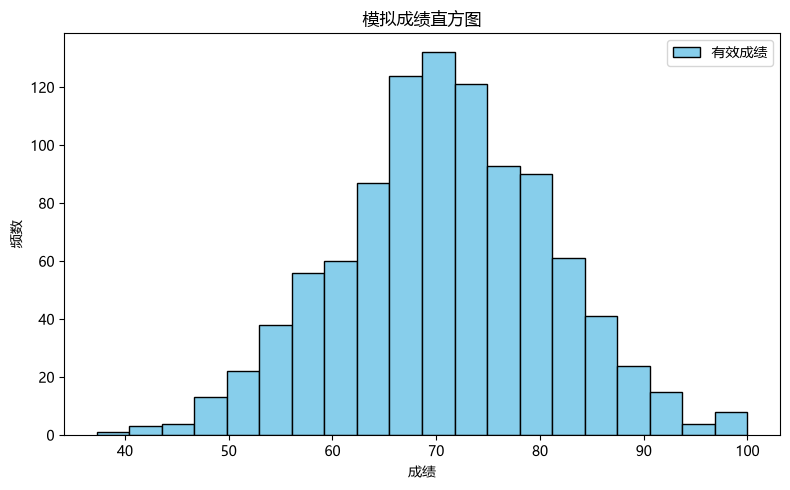

直方图有效成绩数: 997
有效成绩均值: 70.76


In [60]:
valid_scores = scores_df["Score"].dropna()
plt.figure(figsize=(8, 5))
plt.hist(valid_scores, bins=20, color="skyblue", edgecolor="black", label="有效成绩")
plt.title("模拟成绩直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.legend()
plt.tight_layout()
plt.show()
print(f"直方图有效成绩数: {len(valid_scores)}")
print(f"有效成绩均值: {valid_scores.mean():.2f}")

### 任务 3.6：绘制模拟成绩箱线图
箱线图展示成绩分布及四分位数，绘图时排除缺失值。

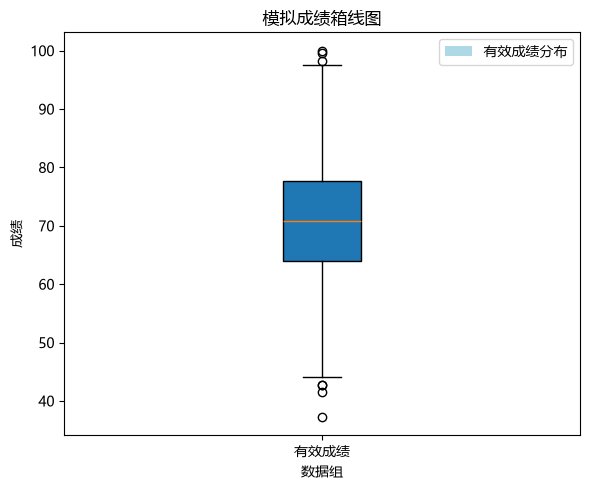

有效成绩中位数: 70.83
第 25 百分位数: 64.02
第 75 百分位数: 77.69


In [61]:
from matplotlib.patches import Patch

valid_scores = scores_df["Score"].dropna()
plt.figure(figsize=(6, 5))
plt.boxplot(valid_scores, tick_labels=["有效成绩"], patch_artist=True)
plt.title("模拟成绩箱线图")
plt.xlabel("数据组")
plt.ylabel("成绩")
plt.legend(handles=[Patch(facecolor="lightblue", label="有效成绩分布")])
plt.tight_layout()
plt.show()
print(f"有效成绩中位数: {valid_scores.median():.2f}")
print(f"第 25 百分位数: {valid_scores.quantile(0.25):.2f}")
print(f"第 75 百分位数: {valid_scores.quantile(0.75):.2f}")

### 任务 3.7：绘制三个函数的折线图
在同一坐标系中绘制 `y=x`、`y=x**2` 和 `y=x**3`，其中 `0 ≤ x ≤ 5`。

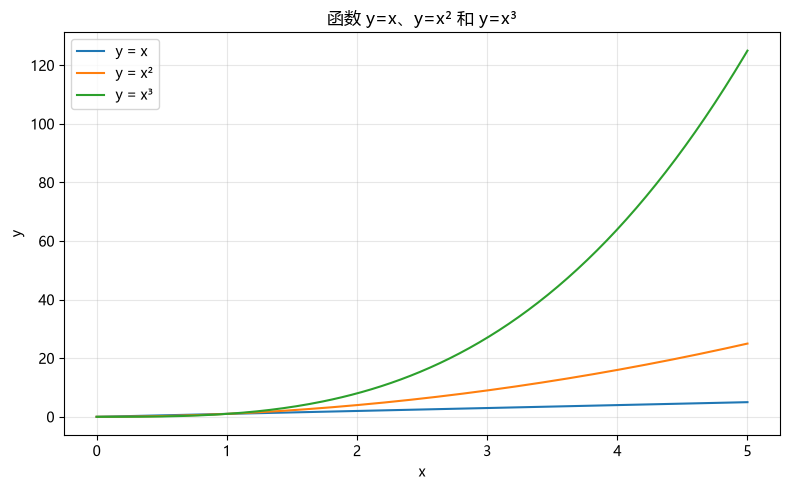

x 的范围: [0.0, 5.0]
绘图点数: 200


In [62]:
x_values = np.linspace(0, 5, 200)
plt.figure(figsize=(8, 5))
plt.plot(x_values, x_values, label="y = x")
plt.plot(x_values, x_values**2, label="y = x²")
plt.plot(x_values, x_values**3, label="y = x³")
plt.title("函数 y=x、y=x² 和 y=x³")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"x 的范围: [{x_values.min():.1f}, {x_values.max():.1f}]")
print(f"绘图点数: {len(x_values)}")

### 任务 4.1：创建 DataFrame 并计算总分与平均分
以姓名作为行索引，新增三科总分和平均分，并查看索引、列名、前三行及统计信息。

In [63]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
students_df = pd.DataFrame(records).set_index("Name")
subjects = ["Math", "English", "Python"]
students_df["Total"] = students_df[subjects].sum(axis=1)
students_df["Average"] = students_df[subjects].mean(axis=1)

print(f"行索引: {students_df.index.tolist()}")
print(f"列名: {students_df.columns.tolist()}")
print("\n前 3 行:")
print(students_df.head(3))
print("\n基本统计信息:")
print(students_df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


### 任务 4.2：使用 loc 和 iloc 索引
`loc` 按标签读取，`iloc` 按位置读取；随后筛选平均分不低于 80 的学生。

In [64]:
carol_position = students_df.index.get_loc("Carol")
print("使用 loc 读取 Carol:")
print(students_df.loc["Carol"])
print("\n使用 iloc 读取 Carol:")
print(students_df.iloc[carol_position])

high_average_students = students_df.loc[students_df["Average"] >= 80]
print("\n平均分不低于 80 的学生:")
print(high_average_students)

使用 loc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

使用 iloc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


### 任务 4.3：计算列均值与行均值
`mean(axis=0)` 按列计算三科平均成绩；`mean(axis=1)` 按行计算每名学生的平均成绩。

In [65]:
subjects = ["Math", "English", "Python"]
column_means = students_df[subjects].mean(axis=0)
row_means = students_df[subjects].mean(axis=1)

print("各科列均值（mean(axis=0)）:")
print(column_means)
print("\n每名学生行均值（mean(axis=1)）:")
print(row_means)

各科列均值（mean(axis=0)）:
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生行均值（mean(axis=1)）:
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


### 任务 4.4：使用 apply、agg 和 rank
计算每名学生的最高分、每科的最小值/均值/最大值，并按数学成绩从高到低排名。

In [66]:
subjects = ["Math", "English", "Python"]
highest_score_by_student = students_df[subjects].apply(max, axis=1)
subject_statistics = students_df[subjects].agg(["min", "mean", "max"])
math_rank = students_df["Math"].rank(ascending=False, method="min")

print("每名学生的三科最高分:")
print(highest_score_by_student)
print("\n各科最小值、均值和最大值:")
print(subject_statistics)
print("\n数学成绩排名（1 为最高）:")
print(math_rank.astype(int).sort_values())

每名学生的三科最高分:
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64

各科最小值、均值和最大值:
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

数学成绩排名（1 为最高）:
Name
Carol    1
Alice    2
Frank    3
Eva      4
Bob      5
David    6
Name: Math, dtype: int64


### 任务 4.5：按组统计并使用 transform
统计各组人数和三科均分，再将每名学生所在组的 Python 平均分添加为新列。

In [67]:
group_statistics = students_df.groupby("Group").agg(
    人数=("Python", "size"),
    数学平均分=("Math", "mean"),
    英语平均分=("English", "mean"),
    Python平均分=("Python", "mean"),
)
students_with_group_mean = students_df.copy()
students_with_group_mean["GroupPythonMean"] = (
    students_with_group_mean.groupby("Group")["Python"].transform("mean")
)

print("各组人数与三科平均分:")
print(group_statistics)
print("\n添加所在组 Python 平均分后的学生表:")
print(students_with_group_mean[["Group", "Python", "GroupPythonMean"]])

各组人数与三科平均分:
       人数      数学平均分      英语平均分  Python平均分
Group                                     
A       3  79.666667  83.333333  87.000000
B       3  80.000000  78.333333  80.333333

添加所在组 Python 平均分后的学生表:
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


### 任务 4.6：使用 groupby 和 filter 筛选组
保留组内 Python 平均分不低于 80 的所有组，并输出这些组及其学生。

In [68]:
filtered_students = students_df.groupby("Group").filter(
    lambda group: group["Python"].mean() >= 80
)
retained_groups = sorted(filtered_students["Group"].unique().tolist())

print(f"保留的组: {retained_groups}")
print("保留组中的学生:")
print(filtered_students[["Group", "Python"]])

保留的组: ['A', 'B']
保留组中的学生:
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82


### 任务 4.7：协方差矩阵与相关系数矩阵
协方差正负表示样本中变量倾向于同向或反向变化；相关系数绝对值越接近 1，线性相关通常越强。

In [69]:
subjects = ["Math", "English", "Python"]
covariance_matrix = students_df[subjects].cov()
correlation_matrix = students_df[subjects].corr()
math_english_covariance = covariance_matrix.loc["Math", "English"]
math_english_correlation = correlation_matrix.loc["Math", "English"]

print("三科成绩协方差矩阵:")
print(covariance_matrix)
print("\n三科成绩皮尔森相关系数矩阵:")
print(correlation_matrix)
print(
    f"\n数学与英语：协方差={math_english_covariance:.3f}，"
    f"相关系数={math_english_correlation:.3f}"
)
if math_english_covariance > 0:
    print("协方差为正：这两科成绩在该样本中总体倾向于同向变化。")
elif math_english_covariance < 0:
    print("协方差为负：这两科成绩在该样本中总体倾向于反向变化。")
else:
    print("协方差为零：该样本中两科成绩的线性共同变化为零。")
print("相关系数绝对值越接近 1，线性相关通常越强；越接近 0，通常越弱。")

三科成绩协方差矩阵:
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

三科成绩皮尔森相关系数矩阵:
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000

数学与英语：协方差=62.567，相关系数=0.654
协方差为正：这两科成绩在该样本中总体倾向于同向变化。
相关系数绝对值越接近 1，线性相关通常越强；越接近 0，通常越弱。


### 任务 4.8：在内存中进行 CSV 写入与读取
使用 `StringIO` 在内存中完成转换，不在磁盘上创建文件。

In [70]:
from io import StringIO

csv_buffer = StringIO()
scores_df.to_csv(
    csv_buffer,
    index_label="SampleNo",
    float_format="%.15f",
)
csv_text = csv_buffer.getvalue()
restored_scores_df = pd.read_csv(
    StringIO(csv_text),
    index_col="SampleNo",
    float_precision="round_trip",
)

print("内存 CSV 文本前 4 行:")
print("\n".join(csv_text.splitlines()[:4]))
print("\n回读表格前 5 行:")
print(restored_scores_df.head())
print(f"\n原表形状: {scores_df.shape}")
print(f"回读后形状: {restored_scores_df.shape}")
print(f"回读后缺失值个数: {restored_scores_df['Score'].isna().sum()}")
print(f"回读后数据与原表一致: {scores_df.equals(restored_scores_df)}")

内存 CSV 文本前 4 行:
SampleNo,Score
1,65.682814796882965
2,56.071260321709367
3,73.115706675062825

回读表格前 5 行:
              Score
SampleNo           
1         65.682815
2         56.071260
3         73.115707
4         69.867651
5         84.497077

原表形状: (1000, 1)
回读后形状: (1000, 1)
回读后缺失值个数: 3
回读后数据与原表一致: True
